## Import all the libraries <a name="import-all-the-libraries"></a>

In [ ]:
#Python default packages
import os
import pwd
import glob
import subprocess
import csv
import random
from concurrent.futures import ProcessPoolExecutor
import concurrent.futures
import multiprocessing
from multiprocessing import Pool, cpu_count
import threading
import signal
import sys
import tempfile
import warnings
from itertools import product
from itertools import combinations
import warnings
import gzip
import shutil
import tarfile
import time

In [2]:
#Python additional packages
#import multiqc
import pysam
from tqdm import tqdm
from bioinfokit.analys import norm
from IPython.display import display, HTML
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import matplotlib.cm as cm
from matplotlib import gridspec
from matplotlib.patches import Patch
import matplotlib.ticker as mticker
import matplotlib.colors as mcolors
from matplotlib.ticker import MaxNLocator
from matplotlib_venn import venn3, venn2
from venn import venn
import pandas as pd
import numpy as np
from Bio import SeqIO
from scipy.stats import rankdata
from scipy.stats import chi2, t, norm
from scipy.stats import pearsonr, spearmanr, kendalltau, multiscale_graphcorr
from statsmodels.distributions.empirical_distribution import ECDF
from scipy.interpolate import interp1d
from scipy.cluster import hierarchy
import scipy.cluster.hierarchy as sch
from scipy.cluster.hierarchy import leaves_list, linkage, dendrogram, fcluster
from scipy.spatial.distance import pdist
from scipy.stats import gamma, norm, poisson, zscore
from scipy.optimize import brentq
from scipy.optimize import minimize
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly.express as px
import webcolors
from webcolors import hex_to_rgb
from collections import OrderedDict
import umap
import hdbscan
%matplotlib inline
# %matplotlib agg
# %matplotlib agg



A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.4.2 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/home/hyunmi/DDA_260806/lib/python3.11/site-packages/ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "/home/hyunmi/DDA_260806/lib/python3.11/site-packages/traitlets/config/application.py", line 1082, in launch_instance
    app.start()
  File "/home/hyunmi/DDA_260806/lib/python3.11/site-packages/ipykernel/kernelapp.py", line 758, in start
    self.io_loop.start()
  File "/home/hy

AttributeError: _ARRAY_API not found

/home/hyunmi/DDA_260806/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
#Python package for R
import rpy2.robjects as robjects
from rpy2.robjects.packages import importr
from rpy2.robjects.vectors import StrVector, FloatVector
from rpy2.robjects import pandas2ri
from rpy2.robjects import FactorVector
from rpy2.robjects.vectors import DataFrame
#pandas2ri.activate()
import rpy2.robjects.numpy2ri as numpy2ri
from rpy2.robjects.conversion import localconverter

/home/hyunmi/DDA_260806/lib/python3.11/site-packages/rpy2/rinterface/__init__.py:1185: UserWarning: Environment variable "BASH_FUNC_ml%%" redefined by R and overriding existing variable. Current: "() {  eval "$($LMOD_DIR/ml_cmd "$@")"
}", R: "() {  eval "$($LMOD_DIR/ml_cmd "$@")"}"
  warnings.warn(
/home/hyunmi/DDA_260806/lib/python3.11/site-packages/rpy2/rinterface/__init__.py:1185: UserWarning: Environment variable "BASH_FUNC_module%%" redefined by R and overriding existing variable. Current: "() {  if [ -z "${LMOD_SH_DBG_ON+x}" ]; then
 case "$-" in 
 *v*x*)
 __lmod_sh_dbg='vx'
 ;;
 *v*)
 __lmod_sh_dbg='v'
 ;;
 *x*)
 __lmod_sh_dbg='x'
 ;;
 esac;
 fi;
 if [ -n "${__lmod_sh_dbg:-}" ]; then
 set +$__lmod_sh_dbg;
 echo "Shell debugging temporarily silenced: export LMOD_SH_DBG_ON=1 for Lmod's output" 1>&2;
 fi;
 eval "$($LMOD_CMD shell "$@")" && eval "$(${LMOD_SETTARG_CMD:-:} -s sh)";
 __lmod_my_status=$?;
 if [ -n "${__lmod_sh_dbg:-}" ]; then
 echo "Shell debugging restarted" 1>&2;
 set

In [4]:
base_dir = "/home/hyunmi/projects/def-dkkim/hyunmi/GEC_proteomics/PG3/"  #######  The output folder for MaxQuant #########
import os
base_dir = os.path.expanduser(base_dir)

In [5]:
# Activate R's base package
base = importr('base')

# Load packages
limma = importr("limma")
edgeR = importr("edgeR")
stats = importr("stats")
Desctools = importr("DescTools")

graphics = importr("graphics")

#Cheking current library Path
robjects.r(".libPaths()")

# Set R's working directory
robjects.r(f'setwd("{base_dir}")')

In [ ]:
# Final category
# A list of the name of groups (sample types)
name_list = ["Tumor", "NAT"]

# Final category
drug_category = {
    "Group 1" : ["Tumor"],
    "Group 2" : ["NAT"],
}

# Final category color code
category_colors = {
    "Group 1" : "#FF0000",   # Tumor -> red
    "Group 2" : "#0000FF",   # NAT   -> blue
}

# Group color code (maps each group name to a color)
drug_color_map = {
    "Tumor" : "#FF0000",   # red
    "NAT"   : "#0000FF",   # blue
}

In [7]:
raw_pep_file = os.path.join(base_dir, "PG3_proteome_data.xlsx")
raw_pep_df = pd.read_excel(raw_pep_file)   # read_csv 대신 read_excel
print(raw_pep_df.shape)
print(raw_pep_df.columns[:5].tolist())

/home/hyunmi/DDA_260806/lib/python3.11/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


(11340, 169)
['GeneSymbol', 'GC012nearbytissue', 'GC012tumor', 'GC022nearbytissue', 'GC022tumor']


In [10]:
# ===== Identify sample columns and assign groups by name suffix =====
# First column is "GeneSymbol", the rest are samples
lfq_cols = [c for c in raw_pep_df.columns if c != "GeneSymbol"]
print("Total sample columns:", len(lfq_cols))

# Assign group by suffix: 'tumor' = Tumor, 'nearbytissue' = NAT
col_to_group = {}
for c in lfq_cols:
    if c.endswith("tumor"):
        col_to_group[c] = "Tumor"
    elif c.endswith("nearbytissue"):
        col_to_group[c] = "NAT"

# Check the result
from collections import Counter
print("Group counts:", Counter(col_to_group.values()))   # Tumor: N, NAT: N
print("Example:", list(col_to_group.items())[:4])

Total sample columns: 168
Group counts: Counter({'NAT': 84, 'Tumor': 84})
Example: [('GC012nearbytissue', 'NAT'), ('GC012tumor', 'Tumor'), ('GC022nearbytissue', 'NAT'), ('GC022tumor', 'Tumor')]


# Dimensional reduction analysis <a name="Dimensional-reduction-analysis"></a>

In [12]:
# Remove proteins that are zero across all samples
mask_all_zero = (raw_pep_df[lfq_cols] == 0).all(axis=1)
filtered_pep_df = raw_pep_df.loc[~mask_all_zero].copy()
print("Proteins before:", len(raw_pep_df), " after filtering:", len(filtered_pep_df))
pep_df = filtered_pep_df[lfq_cols]

# Keep only Tumor and NAT columns (exclude Reference/IS channels) using the mapping
pep_col_sample_Set = [col for col in pep_df.columns 
                      if col_to_group.get(col) in ["Tumor", "NAT"]]
print("Selected samples:", len(pep_col_sample_Set))   # should be 45 (Tumor 23 + NAT 22)

# Transpose: rows = samples, cols = proteins
exp_table_norm_T = pep_df[pep_col_sample_Set].T

# Marker style settings
marker_size = 10
marker_linewidth = 0.5
marker_edgecolor = 'black'
color_grid = 'lightgray'

# Color each sample by its group (Tumor / NAT)
sample_color_dict = {}
for sample in pep_col_sample_Set:
    group = col_to_group.get(sample)          # 'Tumor' or 'NAT'
    sample_color_dict[sample] = drug_color_map.get(group, "#999999")

Proteins before: 11340  after filtering: 11340
Selected samples: 168


In [13]:
# All samples are already colored by group above.
# Build the data matrix for PCA: replace NaN with zeros.
X = exp_table_norm_T.values
X = np.nan_to_num(X)
print("X shape:", X.shape)   # should be (45, number_of_proteins)

X shape: (168, 11340)


## Interactive 2D PCA <a name="Interactive-2D-PCA"></a>

In [15]:
print("X shape:", X.shape)
print("exp_table_norm_T shape:", exp_table_norm_T.shape)
print("exp_table_norm_T index (샘플 이름들):", list(exp_table_norm_T.index)[:10])

X shape: (168, 11340)
exp_table_norm_T shape: (168, 11340)
exp_table_norm_T index (샘플 이름들): ['GC012nearbytissue', 'GC012tumor', 'GC022nearbytissue', 'GC022tumor', 'GC023nearbytissue', 'GC023tumor', 'GC026nearbytissue', 'GC026tumor', 'GC028nearbytissue', 'GC028tumor']


In [16]:
# Perform PCA with 2 components
pca = PCA(n_components=3, 
            random_state= 10000)

# Transformed data to lower dimension
pca_2d = pca.fit_transform(X)

# Assign data to dataframe with index (sample names)
pca_2d = pd.DataFrame(pca_2d, index=exp_table_norm_T.index)

# Assign the columns with a color per sample
pca_2d.columns = ['PC%s (%s' % (i + 1, round(pca.explained_variance_ratio_[i] * 100, 2)) + '%)' for i in range(3)]
pca_2d['Colour'] = [sample_color_dict[sample] for sample in pca_2d.index]
color_discrete_map = {sample: pca_2d.loc[sample, 'Colour'] for sample in pca_2d.index}

fig = px.scatter(pca_2d, 
                 x=pca_2d.columns[0], 
                 y=pca_2d.columns[1],
                 color=pca_2d.index,  # Use tsne_df.index for coloring
                 color_discrete_map=color_discrete_map,  # Map index values to colors
                 hover_name=pca_2d.index)

fig.update_layout(
    width=750,
    height=750,
    autosize=False,
    margin=dict(l=70, r=25, b=100, t=50, pad=0),
    template='plotly_white',
    hovermode='closest',
    xaxis=dict(
        showgrid=True,
        gridcolor=color_grid,
        zerolinecolor=color_grid,
    ),
    yaxis=dict(
        showgrid=True,
        gridcolor=color_grid,
        zerolinecolor=color_grid,
    ),
    #showlegend=False,
    legend=dict(
        title=dict(text='Samples'), borderwidth=0.5, font_size=16,
    )
)

#original version
#fig.update_traces(marker=dict(size=marker_size, 
#                              line=dict(width=marker_linewidth,
#                                        color=marker_edgecolor)),
#                  selector=dict(mode='markers'))

#newversion with transparent dots
fig.update_traces(marker=dict(size=marker_size,
                              opacity=0.6,                    # semi-transparent
                              line=dict(width=marker_linewidth,
                                        color=marker_edgecolor)),
                  selector=dict(mode='markers'))



fig.update_layout(font=dict(family='Arial', size=18, color='black'))

fig.add_shape(
    type='rect',
    xref='paper',
    yref='paper',
    x0=0.014,
    y0=0,
    x1=0.986,
    y1=1,
    line=dict(color='black', width=1), 
    fillcolor='rgba(0,0,0,0)'  
)

fig.show()

#Define the graph path for storing
PCA_2D_Plot_path = os.path.join(base_dir, "2D_PCA.html")
fig.write_html(PCA_2D_Plot_path)
print(f"2D_PCA.html saved to {PCA_2D_Plot_path}")

################################################################

if isinstance(X, pd.DataFrame):
    feature_names = X.columns  # DataFrame에서 feature 이름 추출
else:
    feature_names = [f"Feature_{i}" for i in range(X.shape[1])]

pca_loadings = pd.DataFrame(pca.components_.T,  # Transpose to align with variables
                            columns=['PC1_Loading', 'PC2_Loading', 'PC3_Loading'], 
                            index=feature_names)

pca_loading_file = os.path.join(base_dir, "pca_loadings.csv")
pca_loadings.to_csv(pca_loading_file, index=True)

2D_PCA.html saved to /home/hyunmi/projects/def-dkkim/hyunmi/GEC_proteomics/PG3/2D_PCA.html


In [17]:
X = exp_table_norm_T.values
X = np.nan_to_num(X)

############### my editing ##################
n_samples = X.shape[0]
print(n_samples)
perplexity_value = min(5, n_samples - 1)
#############################################

# Perform t-SNE with 2 components
tsne_data = TSNE(n_components=2, perplexity=perplexity_value, random_state=10000)

tsne = tsne_data.fit_transform(X)

# Create a DataFrame with t-SNE results and sample colors
tsne_df = pd.DataFrame(tsne, index=exp_table_norm_T.index, columns=['TSNE1', 'TSNE2'])
tsne_df['Colour'] = [sample_color_dict[sample] for sample in tsne_df.index]
color_discrete_map = {sample: tsne_df.loc[sample, 'Colour'] for sample in tsne_df.index}

# Create the scatter plot using px.scatter
fig = px.scatter(tsne_df, 
                 x=tsne_df.columns[0], 
                 y=tsne_df.columns[1], 
                 color=tsne_df.index,  # Use tsne_df.index for coloring
                 color_discrete_map=color_discrete_map,  # Map index values to colors
                 hover_name=tsne_df.index)

# Update the layout of the 2D scatter plot
fig.update_layout(
    width=600,
    height=600,
    autosize=False,
    margin=dict(l=70, r=20, b=100, t=50, pad=0),
    template='plotly_white',
    hovermode='closest',
    xaxis_title=tsne_df.columns[0],
    yaxis_title=tsne_df.columns[1],
    showlegend=False,
    legend=dict(orientation='v', x=1.02, y=0.5, xanchor='left', yanchor='middle', title='Samples', borderwidth=0.5, bgcolor='rgba(255, 255, 255, 0.9)', font_size=16),
)

fig.update_traces(marker=dict(size=marker_size, 
                              line=dict(width=marker_linewidth,
                                        color=marker_edgecolor)),
                  selector=dict(mode='markers'))

# Update the font style, size, and color
fig.update_layout(font=dict(family='Arial', size=18, color='black'))

fig.add_shape(
    type='rect',
    xref='paper',
    yref='paper',
    x0=0.014,
    y0=0,
    x1=0.986,
    y1=1,
    line=dict(color='black', width=1), 
    fillcolor='rgba(0,0,0,0)'  
)

#Define the graph path for storing
TSEN_2D_Plot_path = os.path.join(base_dir, "2D_TSEN.html")
fig.write_html(TSEN_2D_Plot_path)
print(f"2D_TSEN.html saved to {TSEN_2D_Plot_path}")

# Show the figure
fig.show()

168


2D_TSEN.html saved to /home/hyunmi/projects/def-dkkim/hyunmi/GEC_proteomics/PG3/2D_TSEN.html


In [18]:
# Check the raw data going into PCA for a few Set-1 vs Set-2 samples
import pandas as pd

check_cols = ['Reporter intensity corrected 1 1',   # Set 1
              'Reporter intensity corrected 1 2',   # Set 2
              'Reporter intensity corrected 1 3']   # Set 3

sub = exp_table_norm_T.loc[check_cols]
print("Shape:", sub.shape)
print("\nHow many zero values per sample:")
print((sub == 0).sum(axis=1))
print("\nHow many non-zero values per sample:")
print((sub != 0).sum(axis=1))
print("\nValue range per sample (min / max / mean):")
print(sub.T.describe().loc[['min','max','mean']])

KeyError: "None of [Index(['Reporter intensity corrected 1 1', 'Reporter intensity corrected 1 2',\n       'Reporter intensity corrected 1 3'],\n      dtype='str')] are in the [index]"

In [19]:
# Count points by group
from collections import Counter
groups = [col_to_group.get(s) for s in pca_2d.index]
print(Counter(groups))
# Show PC1 values sorted, to see the clustering
print(pca_2d.iloc[:, 0].sort_values().head(25))   # lowest PC1 = the clustered NAT side

Counter({'NAT': 84, 'Tumor': 84})
GC080tumor          -7769.907605
GC044tumor          -7620.062442
GC081tumor          -6882.390717
GC046nearbytissue   -6675.214525
GC043tumor          -6567.429241
GC111tumor          -6179.273110
GC115tumor          -6156.361885
GC046tumor          -6095.706474
GC040tumor          -5993.103257
GC069nearbytissue   -5897.208561
GC082nearbytissue   -5612.284920
GC037tumor          -5523.764039
GC040nearbytissue   -5506.769561
GC108tumor          -5500.162845
GC038nearbytissue   -5407.211700
GC041nearbytissue   -5402.820189
GC045tumor          -5385.716370
GC043nearbytissue   -5303.805669
GC051tumor          -5274.884467
GC034tumor          -5270.719477
GC107tumor          -5111.342801
GC115nearbytissue   -5097.848764
GC042tumor          -5040.779542
GC044nearbytissue   -5025.511771
GC038tumor          -4967.899204
Name: PC1 (47.99%), dtype: float64


168


/home/hyunmi/DDA_260806/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


2D_UMAP.svg saved to /home/hyunmi/projects/def-dkkim/hyunmi/GEC_proteomics/PG3/2D_UMAP.svg


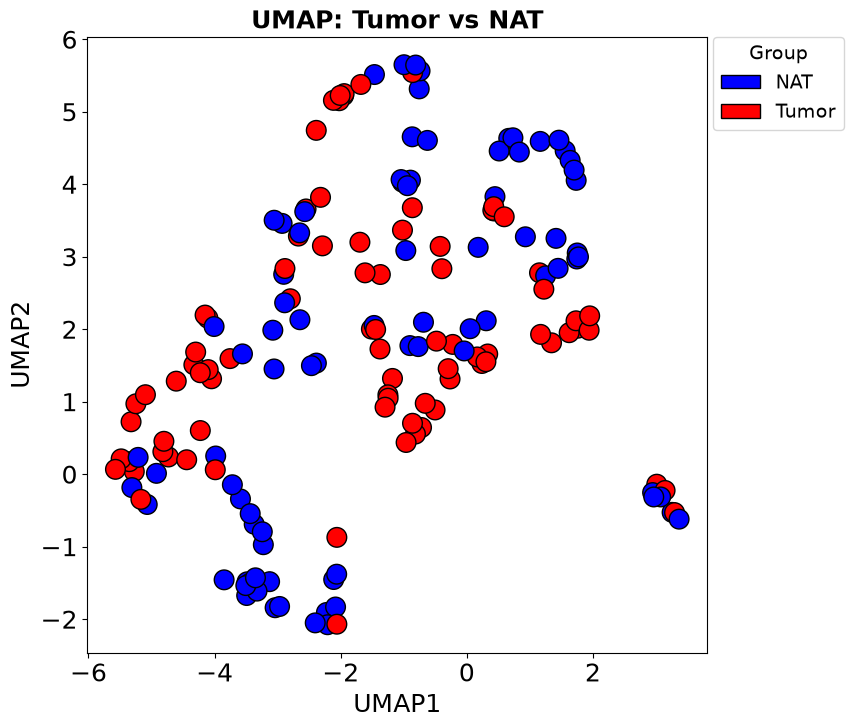

In [20]:
############### my editing ##################
n_samples = X.shape[0]
print(n_samples)
n_neighbors = min(5, n_samples - 1)
#############################################

# Perform UMAP with 2 components
umap_data = umap.UMAP(n_components=2, n_neighbors=n_neighbors,
                      random_state=77, n_epochs=500)
umap_fits = umap_data.fit_transform(X)

# Assign data to dataframe with index (sample names)
umap_2d_df = pd.DataFrame(umap_fits, index=exp_table_norm_T.index, columns=['UMAP1', 'UMAP2'])

# Assign a group (Tumor / NAT) and a color to each sample using the mapping
umap_2d_df['Group'] = [col_to_group.get(s, 'Unknown') for s in umap_2d_df.index]
umap_2d_df['Colour'] = [drug_color_map.get(g, "#999999") for g in umap_2d_df['Group']]

# Create the scatter plot
plt.figure(figsize=(8, 8))
plt.scatter(umap_2d_df['UMAP1'],
            umap_2d_df['UMAP2'],
            c=umap_2d_df['Colour'],
            s=200,
            edgecolors='black',
            linewidth=1.0)

# Build a simple legend: one entry per group (Tumor / NAT)
from matplotlib.patches import Patch
legend_handles = []
for group in umap_2d_df['Group'].unique():
    color = drug_color_map.get(group, "#999999")
    legend_handles.append(Patch(facecolor=color, edgecolor='black', label=group))

# Customize the graph
ax = plt.gca()
ax.grid(False)
ax.set(facecolor="white")
ax.tick_params(axis='both', labelsize=18)
ax.set_xlabel('UMAP1', fontsize=18)
ax.set_ylabel('UMAP2', fontsize=18)
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color('black')

title_font = {'family': 'DejaVu Sans', 'color': 'black', 'weight': 'bold', 'size': 18}
plt.title("UMAP: Tumor vs NAT", fontdict=title_font)

ax.legend(handles=legend_handles, bbox_to_anchor=(1.01, 1.0),
          loc='upper left', prop={'size': 14}, title="Group",
          title_fontsize=14, facecolor='white', borderaxespad=0.)

UMAP_2D_path = os.path.join(base_dir, "2D_UMAP.svg")
plt.savefig(UMAP_2D_path, format='svg', bbox_inches='tight', dpi=300)
print(f"2D_UMAP.svg saved to {UMAP_2D_path}")

plt.show()

/home/hyunmi/DDA_260806/lib/python3.11/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)
/home/hyunmi/DDA_260806/lib/python3.11/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


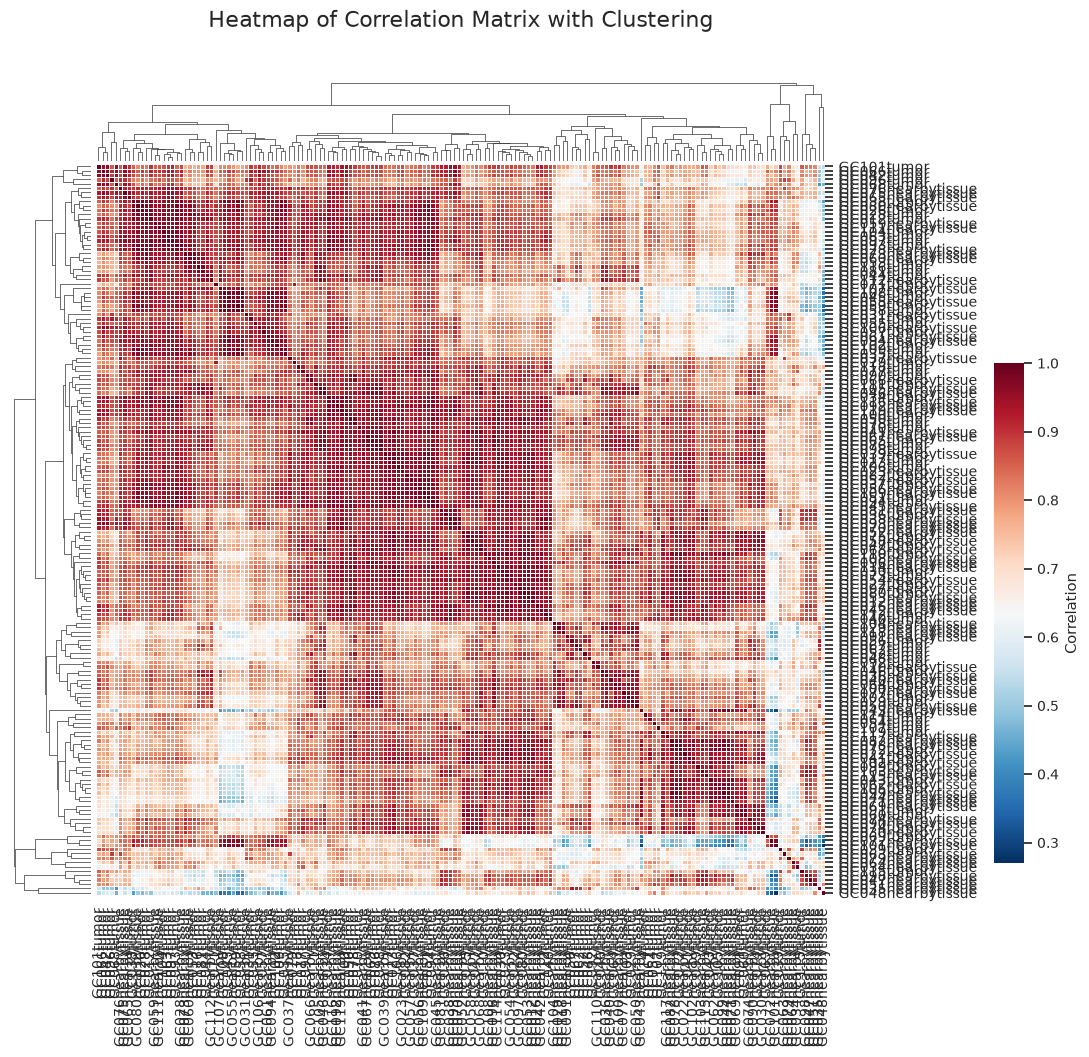

In [21]:
pep_df_filled = pep_df.fillna(0)
cor_matrix_np = pep_df_filled.corr(method='pearson').to_numpy()

# Compute the condensed distance matrix for clustering
dist_matrix = pdist(cor_matrix_np)

# Perform hierarchical clustering with the condensed distance matrix
linkage_matrix = hierarchy.linkage(dist_matrix, method='centroid')  #single, complete, average, weighted, centroid, ward
dendrogram_row = hierarchy.dendrogram(linkage_matrix, no_plot=True)

# Get the order of rows and columns from the dendrogram
order_row = dendrogram_row['leaves']
order_col = dendrogram_row['leaves']

cor_matrix_ordered = cor_matrix_np[order_row][:, order_col]

# Perform hierarchical clusterisng and plot the heatmap with clustering
sns.set(font_scale=0.9)
g = sns.clustermap(
    cor_matrix_np,
    # cor_matrix_ordered,
    cmap='RdBu_r',
    cbar_pos=(1, 0.2, 0.03, 0.5),
    cbar_kws={'label': 'Correlation'},
    dendrogram_ratio=(0.1, 0.1),
    linewidths=0.5,
    xticklabels=np.array(pep_df.columns)[order_row],
    yticklabels=np.array(pep_df.columns)[order_col],
)

# Rotate the x-axis labels for better readability
plt.setp(g.ax_heatmap.get_xticklabels(), rotation=90)

# Set the title above the clustering
g.ax_heatmap.set_title(
    'Heatmap of Correlation Matrix with Clustering',
    fontsize=16, pad=20, loc='center', y=1.15
)

plt.show()


Normalization

In [22]:
def df_to_r_dataframe(df):
    with (robjects.default_converter + pandas2ri.converter).context():
        r_df = robjects.conversion.get_conversion().py2rpy(df)
    return r_df

# Limma quantile normaization 
def limma_normalizeQuantiles(r_dataframe, ties=False):
    normalized_data = limma.normalizeQuantiles(r_dataframe, ties=False)
    return normalized_data

# Winsorization ; the transformation of statistics by limiting extreme values in the statistical data to reduce the effect of possibly spurious outliers.
lower_quantile = 0.00001
upper_quantile = 0.99999
def winsorize_func(r_dataframe, lower_quantile, upper_quantile):
    robjects.r.assign("r_dataframe", r_dataframe)
    result = robjects.r('Winsorize(r_dataframe, na.rm = TRUE, probs = c({}, {}))'.format(lower_quantile, upper_quantile))
    return result

In [24]:
###Quantile normalization
import numpy as np

columns_to_include = [col for col in pep_df.columns 
                      if col_to_group.get(col) in ["Tumor", "NAT"]]
print("Columns to normalize:", len(columns_to_include))
nor_clean_quant = pep_df[columns_to_include].astype(float)

nor_clean_r = df_to_r_dataframe(nor_clean_quant)
nor_clean_quant_r = robjects.r['normalizeQuantiles'](nor_clean_r, ties=True)

quant_np = np.array(nor_clean_quant_r)
print("R result shape (numpy):", quant_np.shape)

if quant_np.shape == nor_clean_quant.shape:
    quantile_df = pd.DataFrame(quant_np, columns=nor_clean_quant.columns, index=nor_clean_quant.index)
elif quant_np.shape == nor_clean_quant.shape[::-1]:
    quantile_df = pd.DataFrame(quant_np.T, columns=nor_clean_quant.columns, index=nor_clean_quant.index)
else:
    raise ValueError(f"Unexpected shape: {quant_np.shape} vs {nor_clean_quant.shape}")

print("quantile_df NaN count:", quantile_df.isna().sum().sum())

######## Option 2) half minimum imputation (min/2) #############
blank_df = quantile_df.replace("", np.nan)
numeric_columns = blank_df.select_dtypes(include=[np.number]).columns
overall_min = blank_df[numeric_columns].min(axis=None, skipna=True)
min_value_half = overall_min / 2
for col in numeric_columns:
    blank_df[col] = blank_df[col].fillna(min_value_half)
quantile_df_halfmin = blank_df

# ---- Build index column (PG3 has "GeneSymbol") ----
index_column = filtered_pep_df[["GeneSymbol"]].copy()
index_column = index_column.rename(columns={"GeneSymbol": "Gene"})
index_column["Protein"] = index_column["Gene"]
index_column["ID"] = index_column["Gene"]

Quantile_df = pd.concat([
    index_column.reset_index(drop=True),
    quantile_df.reset_index(drop=True)
], axis=1)

Quantile_df_halfmin = pd.concat([
    index_column.reset_index(drop=True),
    quantile_df_halfmin.reset_index(drop=True)
], axis=1)

quantile_file = os.path.join(base_dir, "quantile_normalization.csv")
Quantile_df.to_csv(quantile_file, index=True)

quantile_halfmin_file = os.path.join(base_dir, "quantile_halfmin_normalization.csv")
Quantile_df_halfmin.to_csv(quantile_halfmin_file, index=True)

print("Normalization done. Shape:", Quantile_df.shape)

Columns to normalize: 168


R result shape (numpy): (168, 11340)
quantile_df NaN count: 0
Normalization done. Shape: (11340, 171)


In [25]:
# 1. R 정규화 직전 pandas 데이터는 정상인가?
print("=== nor_clean_quant (R 넣기 전) ===")
print("shape:", nor_clean_quant.shape)
print("dtype:", nor_clean_quant.dtypes.value_counts().to_dict())
print("첫 3x2 값:\n", nor_clean_quant.iloc[:3, :2])
print("NaN 개수:", nor_clean_quant.isna().sum().sum())

=== nor_clean_quant (R 넣기 전) ===
shape: (11340, 168)
dtype: {dtype('float64'): 168}
첫 3x2 값:
    GC012nearbytissue  GC012tumor
0           0.051996         0.0
1           0.000000         0.0
2           0.000000         0.0
NaN 개수: 0


/home/hyunmi/DDA_260806/lib/python3.11/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)
/home/hyunmi/DDA_260806/lib/python3.11/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


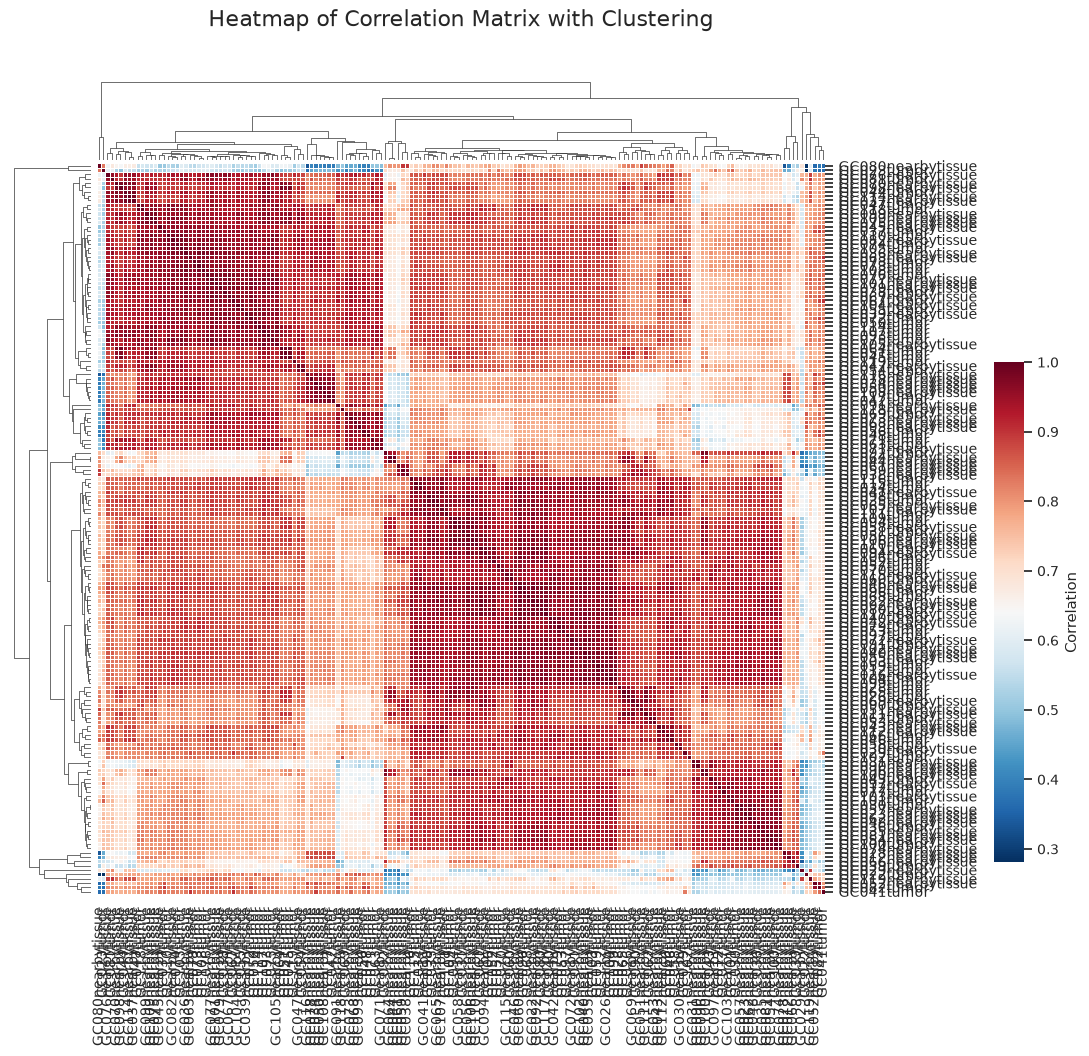

In [26]:
quantile_df_filled = quantile_df.fillna(0)
cor_matrix_np = quantile_df_filled.corr(method='pearson').to_numpy()

# Compute the condensed distance matrix for clustering
dist_matrix = pdist(cor_matrix_np)

# Perform hierarchical clustering with the condensed distance matrix
linkage_matrix = hierarchy.linkage(dist_matrix, method='centroid')  #single, complete, average, weighted, centroid, ward
dendrogram_row = hierarchy.dendrogram(linkage_matrix, no_plot=True)

# Get the order of rows and columns from the dendrogram
order_row = dendrogram_row['leaves']
order_col = dendrogram_row['leaves']

cor_matrix_ordered = cor_matrix_np[order_row][:, order_col]

# Perform hierarchical clusterisng and plot the heatmap with clustering
sns.set(font_scale=0.9)
g = sns.clustermap(
    cor_matrix_np,
    # cor_matrix_ordered,
    cmap='RdBu_r',
    cbar_pos=(1, 0.2, 0.03, 0.5),
    cbar_kws={'label': 'Correlation'},
    dendrogram_ratio=(0.1, 0.1),
    linewidths=0.5,
    xticklabels=np.array(quantile_df.columns)[order_row],
    yticklabels=np.array(quantile_df.columns)[order_col],
)

# Rotate the x-axis labels for better readability
plt.setp(g.ax_heatmap.get_xticklabels(), rotation=90)

# Set the title above the clustering
g.ax_heatmap.set_title(
    'Heatmap of Correlation Matrix with Clustering',
    fontsize=16, pad=20, loc='center', y=1.15
)

plt.show()

Clustering

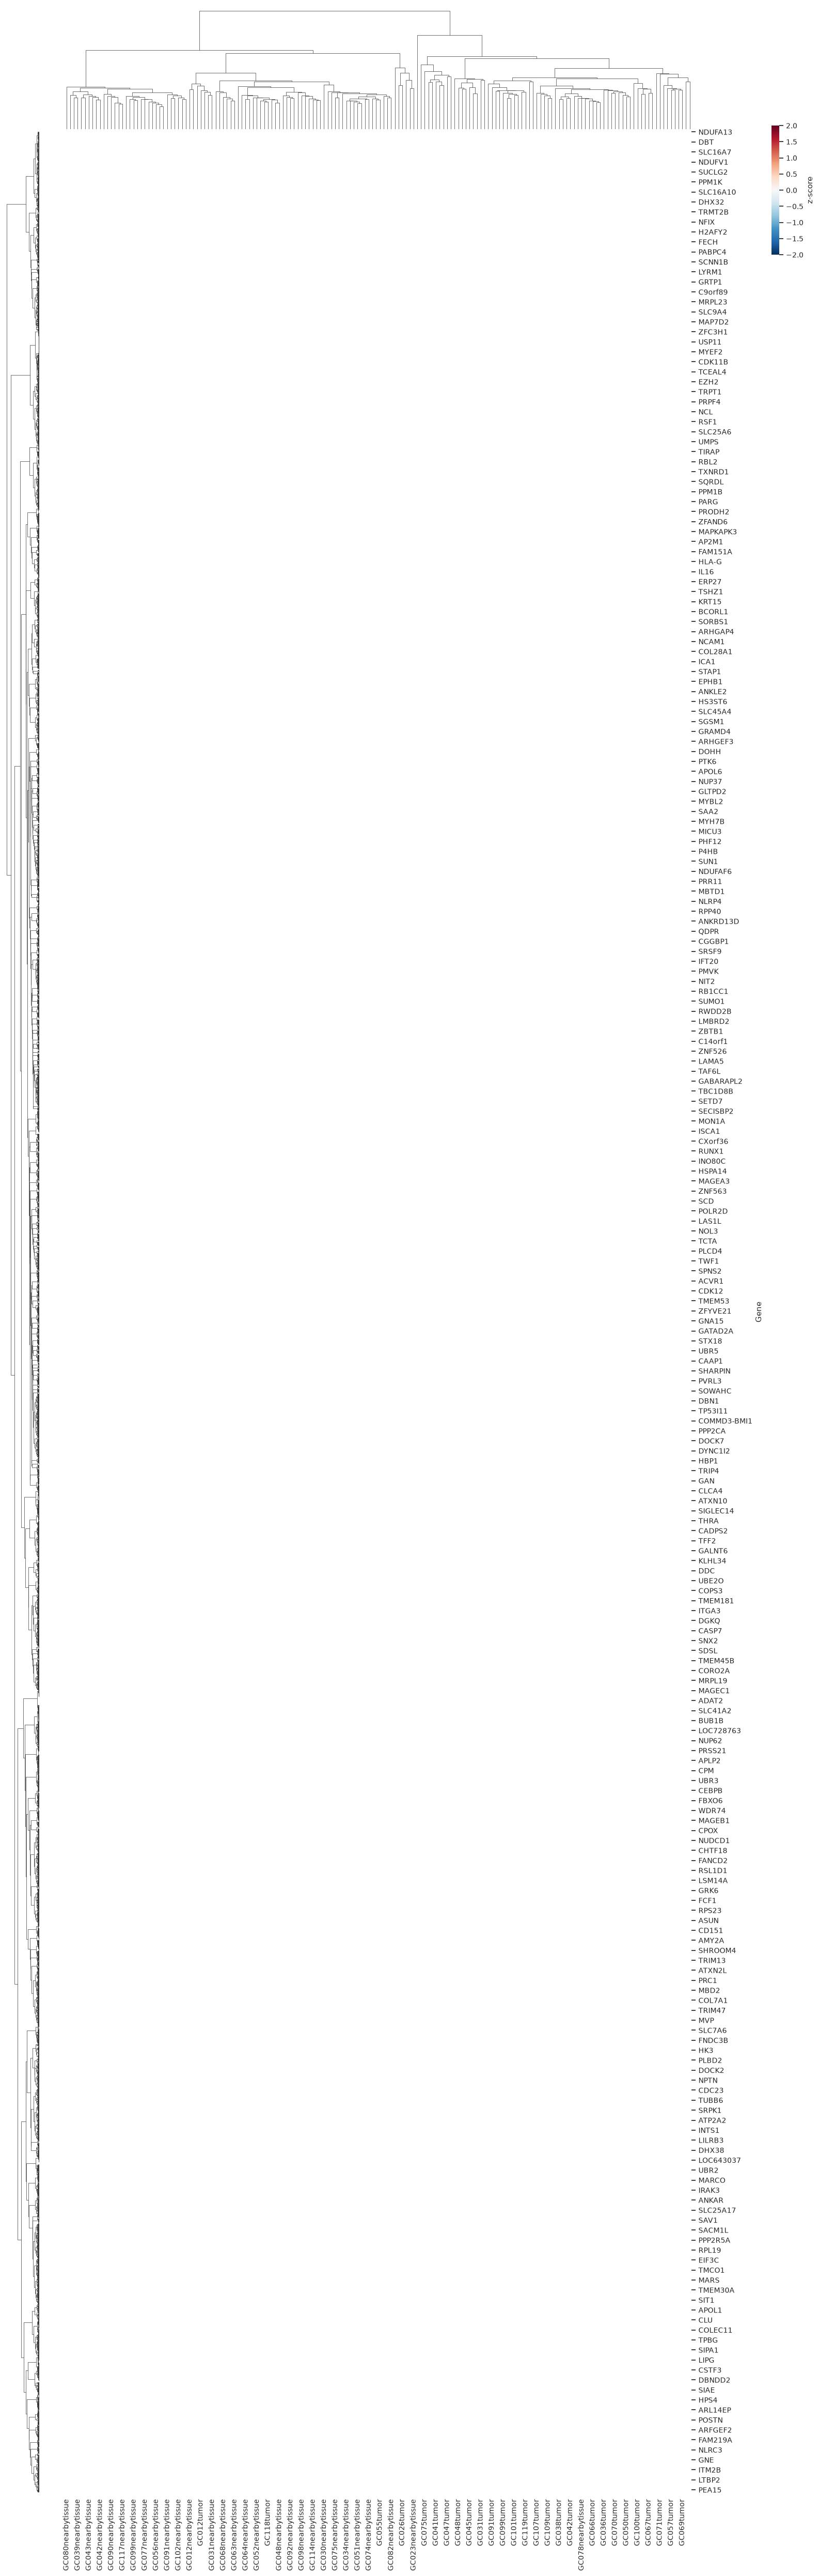

In [27]:
pep_df_copy = Quantile_df.copy()
pep_df_corr = pep_df_copy.drop(columns=['Protein', 'ID'])
pep_df_corr.set_index('Gene', inplace=True)
pep_df_corr.head()

arr = pep_df_corr.values
zarr = zscore(arr, axis=1, ddof=1)
zarr = np.nan_to_num(zarr, nan=0.0, posinf=0.0, neginf=0.0)

normalized_df = pd.DataFrame(
    zarr,
    index=pep_df_corr.index,
    columns=pep_df_corr.columns
)

row_clusters = linkage(normalized_df.values,      method='ward', metric='euclidean')
col_clusters = linkage(normalized_df.values.T,    method='ward', metric='euclidean')

row_clusters_cut = fcluster(row_clusters, t=4, criterion='maxclust')

num_clusters = len(set(row_clusters_cut))
cluster_colors = {
    1: "deeppink",        
    2: "yellow",       
    3: "green",      
    4: "darkviolet"  
}

# Map cluster numbers to colors
row_colors = pd.Series(row_clusters_cut, index=normalized_df.index).map(cluster_colors)

# Add the cluster assignment to the original data for reference
data_with_clusters = normalized_df.copy()
data_with_clusters['Cluster'] = row_clusters_cut

# Sort the data based on the heatmap row order
sorted_idx = leaves_list(row_clusters) 
sorted_data = data_with_clusters.iloc[sorted_idx]

# Heatmap
g = sns.clustermap(
    normalized_df, 
    cmap="RdBu_r", 
    row_linkage=row_clusters, 
    col_linkage=col_clusters,
    linewidths=0.5,
    figsize=(15, 50),
    cbar_kws={'label': 'z-score'},
    dendrogram_ratio=(0.05,0.05),
    cbar_pos=(1,0.9,0.01,0.05),
    row_colors=row_colors,
    center=0, vmin=-2, vmax=2,
)

plt.show()

# Save the cluster assignments along with EntrezID to a CSV file
sorted_data_output_path = os.path.join(base_dir, "clustermap.csv")
sorted_data.reset_index().to_csv(sorted_data_output_path, index=False)

In [28]:
plt.close('all')
%matplotlib agg

sorted_eps_output_path = os.path.join(base_dir, "clustermap.eps")
g.fig.savefig(sorted_eps_output_path, format="eps", bbox_inches="tight")

Empirical test

In [29]:
def Zscore(X):
    # Standardize rows using Z-scores 
    # Z-Score : A numerical measurement that describes a value's relationship to the mean of the group of values and is mesaured in terms of standard deviations from the mean
    # X: numpy ndarray
    
    [m,n] = X.shape # m and n as number of rows and columns 
    mx = np.nanmean(X,axis=0) # Calculate the sample mean for each column, ignoring NaN values
    stdx = np.nanstd(X,axis=0) # Calculate the sample standard deviation for each column, ignoring NaN values 
    ax = np.divide(X - mx, stdx) # Calculate Z-scores to make sure each column has a standard deviation of 1
    return ax

In [30]:
def stat_uneq(x, y):
    # Statistics for identifying DEGs - t-stat, rank-stat and median difference
    # [t-stat,rank,mdiff] = stat2(x,y)
    # Input arguments
    #   x : treatment data (m x nx)
    #   y : control data (m x ny)
    #   All statistical tests are performed by x-y
    # Output arguments
    #   tstat : t-statistic from two sample t-test
    #   rank : statistic from Wilcoxon's ranksum test
    #   mdiff : median difference
    [m, n] = np.shape(x) # Extract the dimensions of the input arrays 'x' and 'y'

    nx = np.sum(~np.isnan(x),axis=1) # Count sum of the non-NaN values in each row of 'x'
    ny = np.sum(~np.isnan(y),axis=1) # Count sum of the non-NaN values in each row of 'y'

    # Median difference (originally median)
    mdiff = np.nanmedian(x,axis=1) - np.nanmedian(y,axis=1) # Calculate the median difference between corresponding columns of 'x' and 'y'

    # two-sample t-test (unequal variance of two groups is assumed)
    difference = np.nanmean(x,axis=1) - np.nanmean(y,axis=1) # Calculate the mean difference between corresponding columns of 'x' and 'y'

    s2x = np.nanvar(x,axis=1) # Calculate the sample variances along each row of 'x'. 
    s2y = np.nanvar(y,axis=1) # Calculate the sample variances along each row of 'y'.
        # Variance: Measure of sample dispersion, it is a measure of how far a set of numbers is spread out from average value

    s2xbar = np.divide(s2x, nx) # Calculate the sample variance per element for 'x'.
    s2ybar = np.divide(s2y, ny) # Calculate the sample variance per element for 'y'.
        # Step is to calculate degree of freedom

    dfe = np.divide(np.power(s2xbar + s2ybar, 2), np.divide(np.power(s2xbar,2), (nx-1)) + np.divide(np.power(s2ybar,2), (ny-1))) 
        # Degree of Freedom: The maximum number of logically indepedent values, which are values that have fredome to vary, in the data sample 
    se = np.sqrt(s2xbar + s2ybar)
        # Standard Error: How far the sample variance deviates from the actual population mean. The larger the sample, the smaller the SE

    t = np.divide(difference, se) # Compute t-statistics 

    # Ranksum Statistic
    r = pd.DataFrame(np.concatenate((x, y),axis=1).T).rank(method='average',axis=0).to_numpy()
        # Rank the transposed and concatenated data, 'x' and 'y', using the 'average' ranking method and convert it to a NumPy array.
    w = np.zeros([m])
        # Initialize an array 'w' with zeros.
    wvar = np.zeros([m])
        # Initialize an array 'wvar' with zeros.

    for i in range(m):
        tmp_nx = nx[i] # Calling loop variable for nx
        tmp_ny = ny[i] # Calling loop variable for ny

        wvar[i] = ((tmp_nx * tmp_ny) * (tmp_nx + tmp_ny + 1)) / 12 # Variance calculation of the rank-sum statistic 
        if tmp_nx <= tmp_ny:
            w[i] = np.nansum(r[0:tmp_nx,i])
            # If treatment is higher than control Calculate 'w' as the sum of ranked values in the first 'tmp_nx' rows of column 'i' in 'r'.
            if np.sum(~np.isnan(r[0:tmp_nx,i])) == 0 :
                w[i] = np.nan
                wvar[i] = np.nan
            # If it is equal to 0, set 'w' and 'wvar' to NaN.
        elif tmp_nx > tmp_ny:
            w[i] = np.nansum(r[tmp_nx:(tmp_nx + tmp_ny),i])
            # If control is higher than treatment, Calculate 'w' as the sum of ranked values in between tmp_nx and tmp_ny rows of column 'i' in 'r'.
            if np.sum(~np.isnan(r[tmp_nx:(tmp_nx + tmp_ny),i])) == 0 :
                w[i] = np.nan
                wvar[i] = np.nan
            # If it is equal to 0, set 'w' and 'wvar' to NaN.

    min_n =np.min(np.c_[nx,ny], axis=1)
        # Calculate the minimum count of non-NaN values between 'nx' and 'ny'.
    
    # Z-Transformation
    wmean = np.multiply(min_n, nx + ny + 1) / 2
        # Calculates the expected mean of the rank-sum statistic under the null hypothesis.
    wc = w - wmean
        # Centers the rank-sum statistic by subtracting the expected mean.
    wz = np.divide(wc - 0.5 * np.sign(wc), np.sqrt(wvar))
        # Standardizes the centered rank-sum statistic using the Z-transformation.

    wz[np.isnan(wz)] = 0
    wz[np.isinf(wz)] = 0
    # set any NaN (Not-a-Number) or infinite values in the Z-transformed rank-sum statistic wz to 0
    t[np.isnan(t)] = 0
    t[np.isinf(t)] = 0
    # set any NaN or infinite values in the t-statistic t to 0

    return t, w, mdiff, wz

# t - array of t-statistics one for each row between treatment group (x) and control group (y). A higher absolute value of t indicates a larger difference between the groups
# w - array of rank-sum statistics between treatment group (x) and control group (y). Quantifies difference by ranks of values within group. A higher absolute value w indicates a larger difference
# mdiff -  array of median difference. Each element represents the difference in medians between the treatment and control groups for each gene. 
# wz - array of Z-transformed rank-sum statistics. Standardize the rank sum to have mean of 0 and standard deviation of 1 under the null hypothesis. This transformation makes it easier to compare the significance of the rank-sum statistics across different genes

In [31]:
def permutation_test(X, treat_num, control_num, Iter_num):
    # X: row - genes (a data matrix with genes in rows and samples in columns)
    # column - samples
    # treat_num (the number of samples in the treatment group)
    # control_num (the number of samples in the control group)
    # Iter_num (the number of permutations to perform)

    X = np.array(X) # Convert genes 
    [row_num, col_num] = X.shape # Determines the number of rows and columns in the data matrix X and stores these values in row_num and col_num.

    try:
        if col_num < (treat_num + control_num):
            # checks if the total number of samples (col_num) is less than the sum of the treatment and control group sizes (treat_num and control_num).
            raise Exception('Total sample number exceeds data matrix column size!')
    except Exception as e:
        print('InputError: ',e)

    # Initialize variables
    t = []  # Initializes an array 't' to store t-statistics for each gene and permutation.
    w = []  # Initializes an array 'w' to store rank-sum statistics for each gene and permutation.
    m = []  # Initializes an array 'm' to store median differences for each gene and permutation.
    wz = [] # Initializes an array 'wz' to store Z-transformed rank-sum statistics for each gene and permutation.
            # Place to store the results of permuation test.

    # Initialize tqdm for progress tracking
    with tqdm(total=Iter_num) as pbar:
        for i in range(Iter_num):
            col_order = np.random.permutation(col_num) # Generates a random permutation of column indices.
            xp = X[:,col_order[0:treat_num]] # Selects the first 'treat_num' columns as the treatment group.
            yp = X[:,col_order[treat_num:treat_num + control_num]] # Selects the next 'control_num' columns as the control group.
            # Calculates various statistics using the 'stat_uneq' function for the shuffled data.
            t_i, w_i, m_i, wz_i = stat_uneq(xp, yp)
            # Append the statistics for this permutation to the respective lists
            t.append(t_i)
            w.append(w_i)
            m.append(m_i)
            wz.append(wz_i)

            # Update tqdm progress
            pbar.update()
    
    # Convert the lists of statistics to NumPy arrays
    t = np.array(t)
    w = np.array(w)
    m = np.array(m)
    wz = np.array(wz)
    
    return t, w, m, wz # Returns arrays containing the results of the permutation test for each gene.

In [32]:
# Define a function realcomp that takes two inputs: x (data) and opt (transformation option).
def realcomp(x,opt):
    # Get the dimensions of the input data matrix 'x'.
    [n, k] = x.shape

    # Check the transformation option 'opt' to determine which transformation to apply.
    if opt == 1:  # Chi-squared transformation
        # Apply the chi-squared transformation to 'x'.
        z = -2 * np.log(x)
        # Count the non-NaN values in each row of the transformed 'z'.
        k = np.sum(~np.isnan(z), axis=1)
        # Calculate the sum of the non-NaN values in each row of 'z'.
        z = np.nansum(z, axis=1)
        # Calculate 'y' values using the chi-squared cumulative distribution function.
        y = 1 - chi2.cdf(z, 2 * k)
    
    elif opt == 2:  # Logit transformation
        # Apply the logit transformation to 'x'.
        z = np.log(np.divide(x, 1 - x))
        # Count the non-NaN values in each row of the transformed 'z'.
        k = np.sum(~np.isnan(z), axis=1)
        # Perform additional calculations on 'z'.
        z = np.multiply(np.nansum(z, axis=1), np.divide(-np.sqrt(15 * k + 12), np.multiply((5 * k + 2), k * np.power(np.pi, 2))))
        # Calculate 'y' values using the t-distribution cumulative distribution function.
        y = 1 - t.cdf(z, 5 * k + 4)
    
    elif opt == 3:  # Standard Normal (Z-Score) Transformation
        # Apply the standard normal transformation to 'x'.
        z = -norm.ppf(x)
        # Count the non-NaN values in each row of the transformed 'z'.
        k = np.sum(~np.isnan(z), axis=1)
        # Perform additional calculations on 'z'.
        z = np.divide(np.nansum(z, axis=1), np.sqrt(k))
        # Calculate 'y' values using the standard normal cumulative distribution function.
        y = 1 - norm.cdf(z)
    
    # Return the computed final trasnformed data 'y' values and the intermediate transformed data 'z', depending on the option.
    return y, z

In [33]:
def vidz(d, opt, idx):
    # Check the number of columns in the input data
    if d.shape[1] > 2:
        # If more than 2 columns, apply transformation using the specified option
        px, _ = np.array(realcomp(d[:,:-1], opt))
    else:
        # If 2 or fewer columns, take the first column as px
        px = d[:,0]

    # Plot the transformed data against the last column of the input data
    plt.plot(px.reshape(px.size, 1), d[:,-1].reshape(d[:,-1].size, 1), 'g.')

    # Mark specific indices on the plot with magenta circles
    plt.plot(px[idx].reshape(px[idx].size, 1), d[idx,-1].reshape(d[idx,-1].size, 1), 'mo')

In [34]:
def nwpv(d,opt):
    # Set a small value for epsilon
    eps = np.finfo(d.dtype).eps

    # Get the dimensions of the input data
    [n, k] = d.shape

    # Iterate over each column in the input data
    for i in range(k):
        # Replace zeros in the column with small values
        tn = np.array(np.where(d[:,i] == 0))
        if np.array(tn).size != 0:
            d[np.where(d[:,i] == 0),i] = np.linspace(1.e-10, eps, len(tn)).T

        # Replace very small values with epsilon
        if np.array(np.where(d[:,i] < eps)).size != 0:
            d[np.where(d[:,i] < eps),i] = eps

        # Replace values close to 1 with a value slightly less than 1
        if np.array(np.where(d[:,i] > 0.99999999999999994)).size != 0:
            d[np.where(d[:,i] > 0.99999999999999994),i] = 0.99999999999999994

    # Apply a transformation to the modified data using the specified option
    [y, z] = realcomp(d, opt)

    # Find indices where the transformed values are less than 0.05
    idx = np.where(y < 0.05)

    # Plot the modified data and mark specific indices
    vidz(d, opt, idx)

    # Return the transformed values and the marked indices
    return y, idx

In [35]:
def pval2tail(s0, s):
    # p-value computation routine
    # s0: null statistic, s: observed statistic
    # p-value: computed by two-tail test

    # Stack the null statistics s0 into a 1D array
    stacked_s0 = np.hstack(s0)

    # Compute the empirical cumulative distribution function (ECDF) for the null statistics
    ecdf_res = ECDF(stacked_s0)

    # Extract unique values (excluding the first one) and their corresponding cumulative probabilities
    s0 = ecdf_res.x[1:]
    f0 = ecdf_res.y[1:]

    # Create a function that interpolates the ECDF values
    f = interp1d(s0, f0, bounds_error=False)

    # Compute the p-value by evaluating the interpolated function at the observed statistic s
    p = f(s)

    # Replace any NaN values in p with 0
    p[np.isnan(p)] = 0

    # Calculate the two-tailed p-value by taking the minimum of p and 1-p and multiplying by 2
    p = 2 * np.min(np.c_[p, 1 - p], axis=1)

    # Handle special cases when p-values are 0 or 1
    if np.sum(p != 0) != 0:
        # If there are non-zero p-values, replace zeros with the smallest non-zero value divided by 2
        p[p == 0] = np.nanmin(p[p != 0]) / 2
    else:
        # If all p-values are zero, replace them with a small non-zero value
        p[p == 0] = 1e-10

    # Adjust p-values that are exactly 1 to ensure they are within [0, 1]
    p[p == 1] = (1 - np.max(p[p != 1])) / 2 + np.max(p[p != 1])

    return p

In [36]:
def pval_calc(trnd, wrnd, mrnd, wzrnd, x, y, pscale, pcomb):
    # Input arguments
    # x: treatment data (m by nx)
    # y: control data (m by ny)
    # pscale: type=bool, if True, scale p-value using Liptak-Stouffer's Z method
    # pcomb: p-value combination option
    #        1 - pt & pm
    #        2 - pwz & pm
    #        3 - pt & pwz & pm

    # Calculate various statistics for treatment and control data
    [tobs, wobs, mobs, wzobs] = stat_uneq(x, y)

    # Calculate one-tailed p-values for different statistics
    pt = pval2tail(trnd, tobs)  # p-value for t-statistic
    pw = pval2tail(wrnd, wobs)  # p-value for ranksum statistic
    pm = pval2tail(mrnd, mobs)   # p-value for median difference
    pwz = pval2tail(wzrnd, wzobs)  # p-value for Z-transformed ranksum statistic

    # Combine p-values based on pcomb option
    if pcomb == 1:
        pall = np.c_[pt, pm]  # Combine t-statistic and median difference p-values
    elif pcomb == 2:
        pall = np.c_[pwz, pm]  # Combine Z-transformed ranksum and median difference p-values
    elif pcomb == 3:
        pall = np.c_[pt, pwz, pm]  # Combine t-statistic, Z-transformed ranksum, and median difference p-values

    # Scale p-values using Liptak-Stouffer's Z method if pscale is True
    if pscale:
        pall = 1 - norm.cdf(Zscore(-norm.ppf(pall)))

    # Calculate overall p-value using non-parametric weighted p-value combination
    ovp = np.array(nwpv(pall, 3)[0])

    return pt, pw, pm, pwz, ovp
# pt represents the one-tailed p-values for the t-statistic. It measures significanace difference between treatment vs control groups, based on means.
# pw is the one-tailed p-value associated with the Wilcoxon rank-sum statistic. This statistic assesses the difference in location (median) between the treatment vs control groups.
# pm is the one-tailed p-value for the median difference between the treatment and control groups. It measures the significance of differences in medians.
# pwz represents the one-tailed p-values for the Z-transformed ranksum statistic. The Z-transform standardizes the ranksum statistic, making it easier to compare significance across genes.

In [37]:
# =====  fold-change + limma stats helpers =====
import os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

# --- R limma 연결 (rpy2) ---
from rpy2.robjects import r, numpy2ri, globalenv
from rpy2.robjects.packages import importr
limma = importr('limma')   
min_n_sample_for_testing = 3   # n<3 p-values are unreliable
FC_CUT, P_CUT = 0.58, 0.05

def calculate_fold_change(group_a, group_b):
    """log2FC = mean(log2(exp+1)) - mean(log2(control+1)). 부호 대칭 정의.
    limma를 쓰면 보통 limma가 낸 logFC를 쓰지만, 검증/호환용으로 남겨둠."""
    log_a = np.log2(np.asarray(group_a, dtype=float) + 1)
    log_b = np.log2(np.asarray(group_b, dtype=float) + 1)
    return np.nanmean(log_b, axis=1) - np.nanmean(log_a, axis=1)

def bh_fdr(p):
    """Benjamini-Hochberg FDR (NaN-safe). limma도 자체 adj.P.Val을 주지만 fallback용."""
    p = np.asarray(p, dtype=float); ok = np.isfinite(p)
    q = np.full(p.shape, np.nan); pv = p[ok]; n = pv.size
    if n == 0: return q
    order = np.argsort(pv); ranked = pv[order]
    adj = ranked * n / np.arange(1, n + 1)
    adj = np.minimum.accumulate(adj[::-1])[::-1]
    out = np.empty(n); out[order] = np.clip(adj, 0, 1); q[ok] = out
    return q

def limma_two_group(ev_log, cv_log):
    """R limma의 lmFit + eBayes(moderated t-test)를 호출.
    ev_log: (n_prot, n_exp), cv_log: (n_prot, n_ctrl)  둘 다 log2 스케일.
    반환: logFC(exp-control 방향), P.Value, adj.P.Val  (numpy array)
    NA는 R에서 그대로 처리(각 단백질 available sample로 적합)."""
    n_ev = ev_log.shape[1]; n_cv = cv_log.shape[1]
    mat = np.hstack([ev_log, cv_log])                 # 단백질 x 샘플
    # group dummy: exp=1, control=0  → coef2가 exp-control 방향 (부호 그대로 사용)
    group = np.array([1]*n_ev + [0]*n_cv, dtype=float)

    globalenv['mat']   = numpy2ri.py2rpy(mat)
    globalenv['grp']   = numpy2ri.py2rpy(group)
    r('''
        design <- model.matrix(~ grp)          # intercept + grp
        fit <- lmFit(mat, design)
        fit <- eBayes(fit, trend=TRUE, robust=TRUE)   # trend/robust: 프로테오믹스 권장
        tt  <- topTable(fit, coef=2, number=Inf, sort.by="none")
    ''')
    tt = r('as.data.frame(tt)')
    # rpy2 DataFrame → 컬럼 추출
    cols = list(tt.colnames)
    def col(name):
        return np.asarray(tt.rx2(name))
    logFC = col('logFC')
    pval  = col('P.Value')
    padj  = col('adj.P.Val')
    return logFC, pval, padj

def run_comparison(control_cols, exp_cols, label, up_lbl, down_lbl):
    cv_all = Quantile_df[control_cols].values.astype(float)
    ev_all = Quantile_df[exp_cols].values.astype(float)

    n_cv = np.isfinite(cv_all).sum(1); n_ev = np.isfinite(ev_all).sum(1)
    var_cv = np.nanvar(cv_all, 1); var_ev = np.nanvar(ev_all, 1)
    # 두 그룹 모두 반복수 충분 + 최소한의 분산 → degenerate 제외
    valid = (n_cv >= min_n_sample_for_testing) & (n_ev >= min_n_sample_for_testing) \
            & ((var_cv > 0) | (var_ev > 0))
    print(f"  Valid proteins: {int(valid.sum())}/{len(valid)} "
          f"(dropped {int((~valid).sum())} degenerate)")

    cv, ev = cv_all[valid], ev_all[valid]
    ann = Quantile_df.loc[valid, ['Gene', 'Protein', 'ID']].reset_index(drop=True)

    # --- limma moderated t-test (log2 스케일 입력) ---
    cv_log = np.log2(cv + 1)
    ev_log = np.log2(ev + 1)
    fc, pval, padj = limma_two_group(ev_log, cv_log)   # fc는 exp-control 방향 log2FC
    pval = np.asarray(pval, dtype=float)
    pval[~np.isfinite(pval)] = 1.0
    padj = np.asarray(padj, dtype=float)

    res = pd.concat([ann, pd.DataFrame(
        {"Fold_Change": fc, "P_Value": pval, "P_adj": padj})], axis=1)
    out = os.path.join(base_dir, f"DEP_limma_{label}.csv")
    res.to_csv(out, index=False); print("  Saved:", out)

    # 유의성: limma의 FDR(P_adj) 기준 권장. (원하면 pval로 바꿔도 됨)
    up   = (padj < P_CUT) & (fc >  FC_CUT)
    down = (padj < P_CUT) & (fc < -FC_CUT)

    plt.figure(figsize=(8, 8))
    plt.scatter(fc, -np.log10(pval), c='lightgray', alpha=0.5, s=10)
    plt.scatter(fc[up],   -np.log10(pval[up]),   c='crimson',   alpha=0.7, s=12, label=f'{up_lbl} ({int(up.sum())})')
    plt.scatter(fc[down], -np.log10(pval[down]), c='royalblue', alpha=0.7, s=12, label=f'{down_lbl} ({int(down.sum())})')
    plt.axhline(-np.log10(P_CUT), color='gray', ls='--')
    plt.axvline(-FC_CUT, color='gray', ls='--'); plt.axvline(FC_CUT, color='gray', ls='--')
    plt.xlabel('log2(Fold Change)'); plt.ylabel('-log10(p-value)')
    plt.title(f'Volcano: {label}')
    xmax = np.nanmax(np.abs(fc)) * 1.1
    plt.xlim([-xmax, xmax]); plt.ylim(bottom=0)
    plt.savefig(os.path.join(base_dir, f"volcano_{label}.png"), dpi=150, bbox_inches='tight')
    plt.show()   # 노트북에 인라인 표시 (안 뜨면 위 한 줄을 plt.close()로)
    print(f"  [{label}] up={int(up.sum())}, down={int(down.sum())}, min_p={np.nanmin(pval):.2e}")
    return res

In [40]:
# =====  tumor VS normal=====
from collections import Counter

CONTROL_STAGE = "NAT"           # nearbytissue
COMPARISONS   = ["Tumor"]       # tumor

# 발현 컬럼 = GeneSymbol 제외 전부, 이름 끝으로 그룹 판별
data_cols = [c for c in Quantile_df.columns if c != 'GeneSymbol']
col_to_stage = {}
for c in data_cols:
    cs = str(c)
    if cs.endswith('nearbytissue'):
        col_to_stage[cs] = 'NAT'
    elif cs.endswith('tumor'):
        col_to_stage[cs] = 'Tumor'

# 확인
mapped = [c for c in Quantile_df.columns if str(c) in col_to_stage]
print(f"매핑되는 컬럼: {len(mapped)} / {len(Quantile_df.columns)}")
print("그룹별 수:", Counter(col_to_stage[str(c)] for c in mapped))

def get_stage_cols(stage):
    return [c for c in Quantile_df.columns if col_to_stage.get(str(c)) == stage]

control_cols = get_stage_cols(CONTROL_STAGE)
print(f"{CONTROL_STAGE} (control): {len(control_cols)} samples")

for EXP_STAGE in COMPARISONS:
    exp_cols = get_stage_cols(EXP_STAGE)
    print(f"\n===== {CONTROL_STAGE} vs {EXP_STAGE} =====  {EXP_STAGE}: {len(exp_cols)} samples")
    if not exp_cols:
        print("  (no samples, skipping)"); continue
    run_comparison(control_cols, exp_cols,
                   f"{CONTROL_STAGE}_vs_{EXP_STAGE}",
                   f"Up in {EXP_STAGE}", f"Down in {EXP_STAGE}")

print("\n===== All comparisons done =====")

매핑되는 컬럼: 168 / 171
그룹별 수: Counter({'NAT': 84, 'Tumor': 84})
NAT (control): 84 samples

===== NAT vs Tumor =====  Tumor: 84 samples
  Valid proteins: 11340/11340 (dropped 0 degenerate)


  Saved: /home/hyunmi/projects/def-dkkim/hyunmi/GEC_proteomics/PG3/DEP_limma_NAT_vs_Tumor.csv
  [NAT_vs_Tumor] up=546, down=638, min_p=1.51e-45

===== All comparisons done =====


In [42]:
print("전체 컬럼 목록:")
print(list(raw_pep_df.columns))
print()
# 발현 컬럼 후보 찾기
for kw in ['LFQ intensity', 'Reporter intensity corrected', 'Intensity', 'Ratio', 'Abundance']:
    hits = [c for c in raw_pep_df.columns if str(c).startswith(kw)]
    if hits:
        print(f"'{kw}' 로 시작하는 컬럼: {len(hits)}개")
        print("  예시:", hits[:6])

전체 컬럼 목록:
['GeneSymbol', 'GC012nearbytissue', 'GC012tumor', 'GC022nearbytissue', 'GC022tumor', 'GC023nearbytissue', 'GC023tumor', 'GC026nearbytissue', 'GC026tumor', 'GC028nearbytissue', 'GC028tumor', 'GC029nearbytissue', 'GC029tumor', 'GC030nearbytissue', 'GC030tumor', 'GC031nearbytissue', 'GC031tumor', 'GC034nearbytissue', 'GC034tumor', 'GC035nearbytissue', 'GC035tumor', 'GC036nearbytissue', 'GC036tumor', 'GC037nearbytissue', 'GC037tumor', 'GC038nearbytissue', 'GC038tumor', 'GC039nearbytissue', 'GC039tumor', 'GC040nearbytissue', 'GC040tumor', 'GC041nearbytissue', 'GC041tumor', 'GC042nearbytissue', 'GC042tumor', 'GC043nearbytissue', 'GC043tumor', 'GC044nearbytissue', 'GC044tumor', 'GC045nearbytissue', 'GC045tumor', 'GC046nearbytissue', 'GC046tumor', 'GC047nearbytissue', 'GC047tumor', 'GC048nearbytissue', 'GC048tumor', 'GC050nearbytissue', 'GC050tumor', 'GC051nearbytissue', 'GC051tumor', 'GC052nearbytissue', 'GC052tumor', 'GC053nearbytissue', 'GC053tumor', 'GC054nearbytissue', 'GC054tum